In [10]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, accuracy_score

dfcsv = pd.read_csv("/content/drive/MyDrive/ML PROJ101/coral_clean_global.csv")

columns_to_drop = ['sample_id', 'site_id', 'date', 'percent_bleaching', 'bleached', 'is_sea', 'is_thailand','data_source']
df = dfcsv.drop(columns=[col for col in columns_to_drop if col in dfcsv.columns], errors='ignore')

df.head()

,country_name,tsa_dhw,ssta_dhw,tsa,ssta,ssta_frequency,tsa_frequency,climsst,temperature_c,temperature_maximum,...,exposure,cyclone_frequency,windspeed,latitude_degrees,longitude_degrees,ocean_name,realm_name,date_year,date_month,bleach_class
0,Chile,NaN,NaN,NaN,NaN,NaN,NaN,21.50,NaN,26.98,...,Exposed,50.08,NaN,-27.1667,-109.3333,Pacific,Eastern Indo-Pacific,1980,6,severe
1,Chile,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.81,...,Exposed,50.08,NaN,-27.1000,-109.3000,Pacific,Eastern Indo-Pacific,1980,6,severe
2,Panama,1.16,8.34,0.80,1.33,11.0,1.0,28.87,30.12,31.27,...,Sheltered,50.00,5.0,7.8128,-81.7597,Pacific,Tropical Eastern Pacific,1983,1,severe
3,Ecuador,5.09,35.44,2.70,4.09,30.0,3.0,24.69,28.62,30.30,...,Exposed,50.21,4.0,-0.7167,-89.2333,Pacific,Tropical Eastern Pacific,1983,1,severe
4,Ecuador,5.31,37.14,2.91,4.48,27.0,4.0,24.49,28.79,30.39,...,Exposed,50.18,4.0,-0.8167,-89.5333,Pacific,Tropical Eastern Pacific,1983,1,severe


In [11]:
df_clean = df.dropna().copy()

target_col = df_clean.columns[-1]

X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

X_encoded = pd.get_dummies(X, drop_first=True)

print(f"จำนวนแถวหลังดรอป NaN: {df_clean.shape[0]}")
print(f"จำนวนฟีเจอร์หลังจากทำ One-Hot Encoding: {X_encoded.shape[1]}")
display(X_encoded.head())

จำนวนแถวหลังดรอป NaN: 17502
จำนวนฟีเจอร์หลังจากทำ One-Hot Encoding: 110


,tsa_dhw,ssta_dhw,tsa,ssta,ssta_frequency,tsa_frequency,climsst,temperature_c,temperature_maximum,turbidity,...,ocean_name_Indian,ocean_name_Pacific,ocean_name_Red Sea,realm_name_Eastern Indo-Pacific,realm_name_Temperate Australasia,realm_name_Temperate Northern Atlantic,realm_name_Temperate Northern Pacific,realm_name_Tropical Atlantic,realm_name_Tropical Eastern Pacific,realm_name_Western Indo-Pacific
5,0.00,13.12,0.78,1.33,14.0,1.0,29.00,30.25,31.74,0.0964,...,False,True,False,False,False,False,False,False,True,False
11,0.00,10.95,0.51,1.37,12.0,4.0,29.19,30.46,32.52,0.0743,...,False,True,False,False,False,False,False,False,False,False
13,30.98,35.63,2.07,3.71,39.0,18.0,24.26,28.17,31.10,0.0623,...,False,True,False,False,False,False,False,False,True,False
14,4.34,4.73,-0.53,0.38,13.0,3.0,28.21,28.74,31.64,0.0934,...,True,False,False,False,False,False,False,False,False,True
20,0.00,0.00,-0.62,-0.27,1.0,0.0,29.71,29.24,32.49,0.0577,...,False,False,False,False,False,False,False,True,False,False


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

print(f"Train set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Train set shape: (14001, 110)
Test set shape: (3501, 110)


In [13]:
# Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("=== Decision Tree Classifier Report ===")
print(classification_report(y_test, dt_pred))
print(f"Accuracy: {accuracy_score(y_test, dt_pred):.4f}")

# Random Forest
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("\n=== Random Forest Classifier Report ===")
print(classification_report(y_test, rf_pred))
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}")

=== Decision Tree Classifier Report ===
              precision    recall  f1-score   support

        mild       0.75      0.73      0.74      1573
        none       0.78      0.80      0.79      1481
      severe       0.66      0.64      0.65       447

    accuracy                           0.75      3501
   macro avg       0.73      0.72      0.73      3501
weighted avg       0.75      0.75      0.75      3501

Accuracy: 0.7492

=== Random Forest Classifier Report ===
              precision    recall  f1-score   support

        mild       0.79      0.77      0.78      1573
        none       0.81      0.87      0.84      1481
      severe       0.75      0.64      0.69       447

    accuracy                           0.80      3501
   macro avg       0.79      0.76      0.77      3501
weighted avg       0.80      0.80      0.80      3501

Accuracy: 0.7981


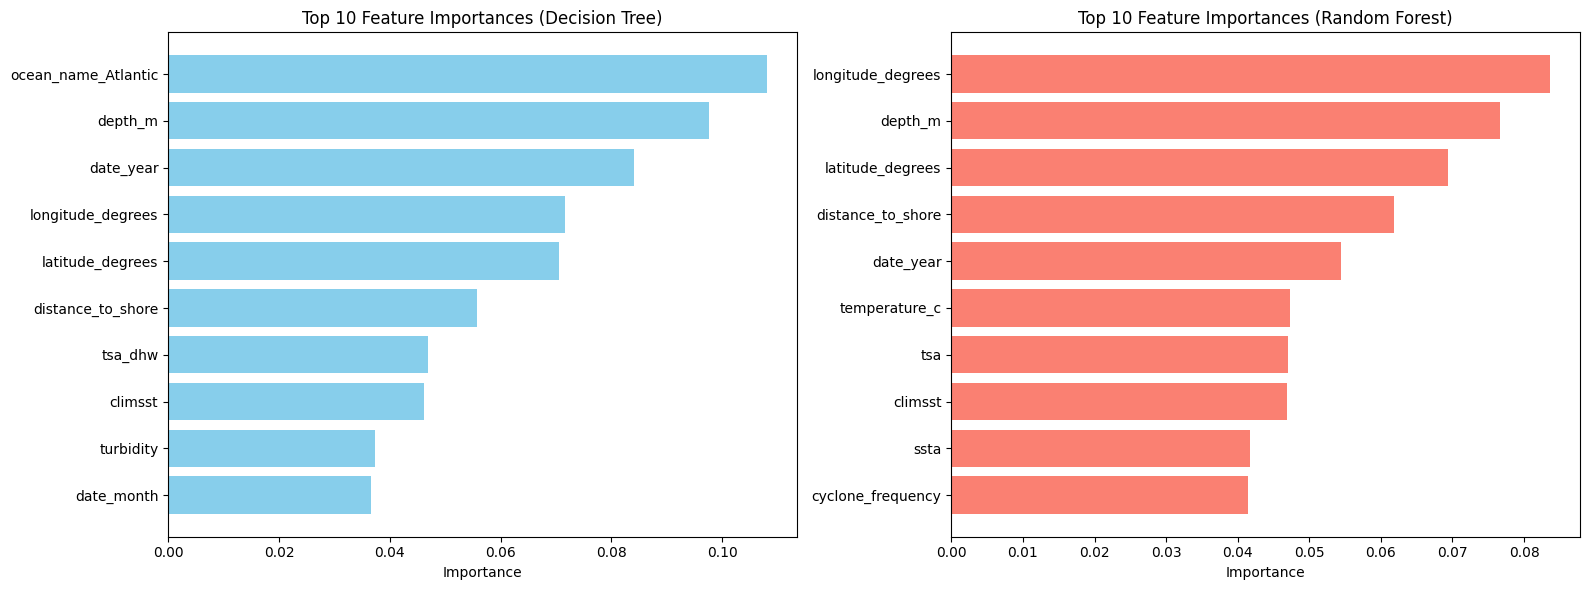

In [14]:
import matplotlib.pyplot as plt

dt_importances = dt_model.feature_importances_
rf_importances = rf_model.feature_importances_
features = X_encoded.columns

indices_dt = np.argsort(dt_importances)[::-1][:10]
indices_rf = np.argsort(rf_importances)[::-1][:10]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(range(10), dt_importances[indices_dt][::-1], align='center', color='skyblue')
axes[0].set_yticks(range(10))
axes[0].set_yticklabels([features[i] for i in indices_dt][::-1])
axes[0].set_title('Top 10 Feature Importances (Decision Tree)')
axes[0].set_xlabel('Importance')

axes[1].barh(range(10), rf_importances[indices_rf][::-1], align='center', color='salmon')
axes[1].set_yticks(range(10))
axes[1].set_yticklabels([features[i] for i in indices_rf][::-1])
axes[1].set_title('Top 10 Feature Importances (Random Forest)')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

In [15]:
!pip install shap

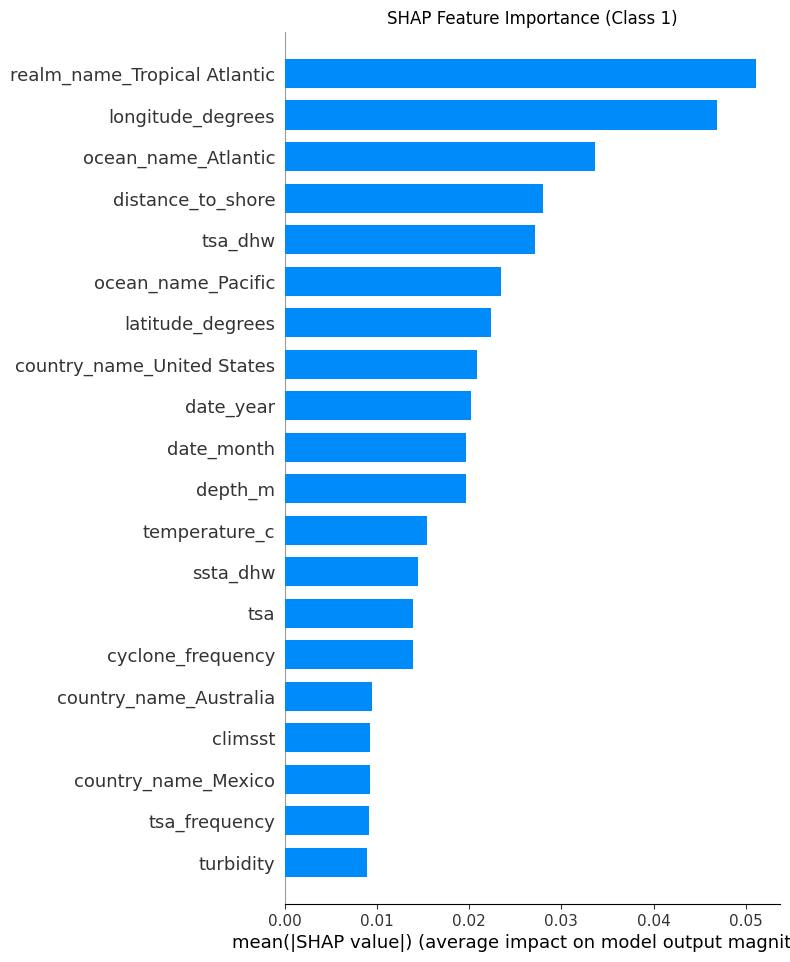

In [16]:
import shap

explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(X_test.iloc[:100])

shap_values_class1 = shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values[1]

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_test.iloc[:100], plot_type="bar", show=False)
plt.title("SHAP Feature Importance (Class 1)")
plt.show()

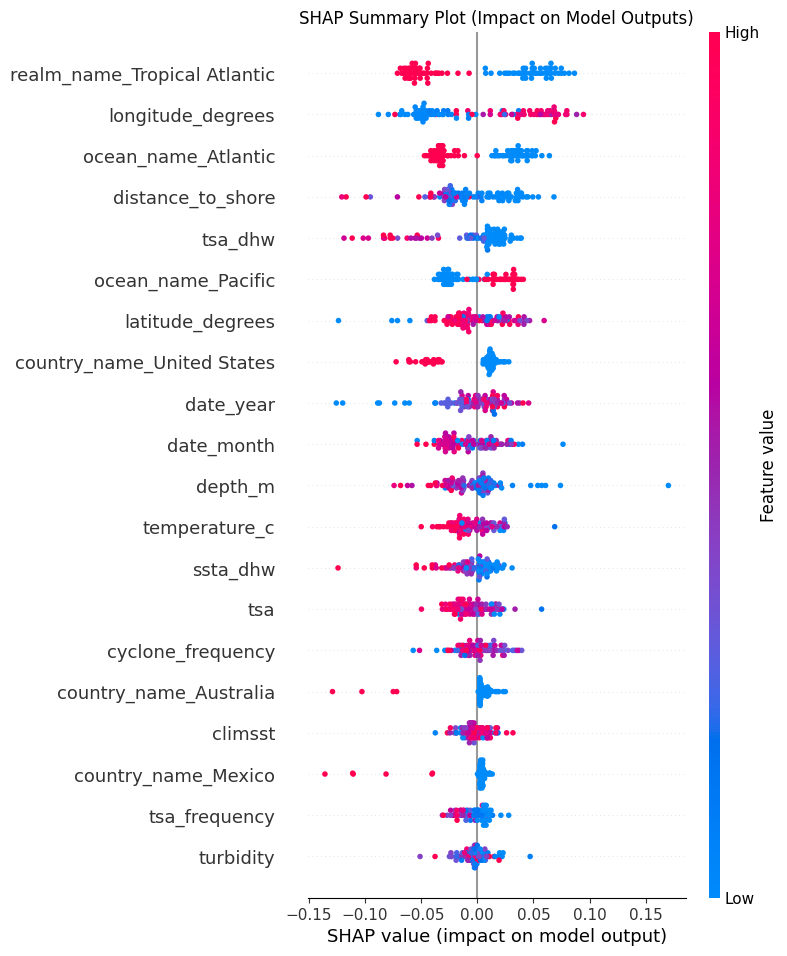

In [17]:
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_test.iloc[:100], show=False)
plt.title("SHAP Summary Plot (Impact on Model Outputs)")
plt.show()